# Credit Card Fraud Detection
Goal: predict whether a card transaction is fraudulent.
Why it matters: fraud is very rare, but every missed case is a direct loss; every false alarm costs an analyst's time and bothers a customer.

The dataset (Kaggle "Credit Card Fraud Detection", `creditcard.csv`) is not part of the repository; see `data/README.md`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TARGET = "Class"

In [2]:
def load_data(path):
    return pd.read_csv(path)

# The CSV is not part of the repository (see data/README.md). Set CREDITCARD_CSV to override.
CANDIDATE_PATHS = [
    os.environ.get("CREDITCARD_CSV", ""),
    "../data/creditcard.csv",
    "data/creditcard.csv",
    "/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv",
]
DATA_PATH = next(p for p in CANDIDATE_PATHS if p and os.path.exists(p))

df = load_data(DATA_PATH)
print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print()

print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(5))
print()

print(df[['Time', 'Amount']].describe().round(2))

Total missing values: 0


Duplicated rows: 1081

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64

            Time     Amount
count  284807.00  284807.00
mean    94813.86      88.35
std     47488.15     250.12
min         0.00       0.00
25%     54201.50       5.60
50%     84692.00      22.00
75%    139320.50      77.16
max    172792.00   25691.16


In [4]:
# 1) Which class do the duplicated rows belong to?
dup = df.duplicated()
print("Duplicates by class:")
print(dup.groupby(df[TARGET]).sum().to_dict())
print("Frauds left after dropping duplicates:", (~dup & (df[TARGET] == 1)).sum())
print()

# 2) Accuracy of a model that always predicts "normal"
print("Accuracy of always predicting 'normal':", round((df[TARGET] == 0).mean(), 5))
print()

# 3) Time: how many hours, and how does fraud vary by hour?
df['Hour'] = (df['Time'] // 3600).astype(int)
hourly = df.groupby('Hour')[TARGET].agg(['count', 'sum'])
hourly['rate_%'] = (hourly['sum'] / hourly['count'] * 100).round(2)
hourly.columns = ['transactions', 'frauds', 'rate_%']
print(hourly.T.to_string())
print()

# 4) If we split by time 80/20, how many frauds end up in the test part?
sorted_df = df.sort_values('Time')
cut = int(len(sorted_df) * 0.8)
print("Time split: train frauds =", sorted_df.iloc[:cut][TARGET].sum(),
      "| test frauds =", sorted_df.iloc[cut:][TARGET].sum())
print()

# 5) Amount by class
print(df.groupby(TARGET)['Amount'].describe().round(2))

Duplicates by class:
{0: 1062, 1: 19}
Frauds left after dropping duplicates: 473

Accuracy of always predicting 'normal': 0.99827

Hour               0        1        2        3        4        5        6        7       8        9        10      11       12       13       14       15       16       17       18       19       20       21       22       23       24      25       26       27       28      29       30      31       32       33       34       35      36      37       38       39       40       41       42       43       44       45       46       47
transactions  3963.00  2217.00  1576.00  1821.00  1082.00  1681.00  1831.00  3368.00  5179.0  7878.00  8288.00  8517.0  7732.00  7585.00  8029.00  7836.00  7786.00  7882.00  8607.00  7994.00  8980.00  9895.00  8977.00  6082.00  3732.00  2003.0  1752.00  1671.00  1127.00  1309.0  2270.00  3875.0  5097.00  7960.00  8310.00  8339.00  7688.0  7780.0  8541.00  8625.00  8667.00  8284.00  8432.00  7655.00  7776.00  7808.00  6464.00  4

### First observations
- 284,807 transactions, 492 frauds (0.173%); no missing values.
- A model that predicts "normal" for everything gets 99.83% accuracy, so accuracy is meaningless. I will use PR-AUC and recall/precision.
- 1,081 duplicated rows; because of the train/test leakage risk, their class distribution is checked and a decision is made below.
- Time spans 0-172,792 s (~48 hours): the data covers only two days.
- Amount is very skewed (median 22, mean 88, maximum 25,691).
- A 20% test set holds only about 98 frauds (75 when splitting the raw data by time), so a single split is noisy; CV will be used.

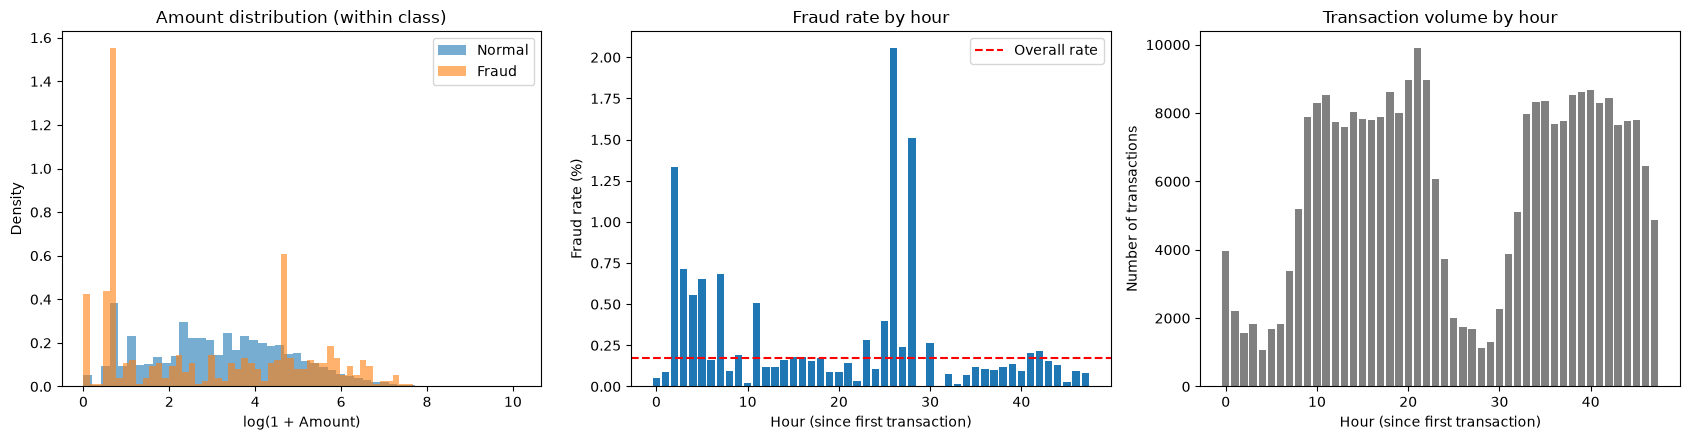

V14    0.949
V4     0.938
V12    0.937
V11    0.918
V10    0.914
V3     0.912
V2     0.855
V16    0.847
V9     0.844
V7     0.836
dtype: float64

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Amount distribution (log scale), density within each class
for cls, label in [(0, 'Normal'), (1, 'Fraud')]:
    axes[0].hist(np.log1p(df.loc[df[TARGET] == cls, 'Amount']),
                 bins=50, alpha=0.6, density=True, label=label)
axes[0].set_xlabel('log(1 + Amount)')
axes[0].set_ylabel('Density')
axes[0].set_title('Amount distribution (within class)')
axes[0].legend()

# 2) Fraud rate by hour
rate = df.groupby('Hour')[TARGET].mean() * 100
axes[1].bar(rate.index, rate.values)
axes[1].axhline(df[TARGET].mean() * 100, color='red', linestyle='--', label='Overall rate')
axes[1].set_xlabel('Hour (since first transaction)')
axes[1].set_ylabel('Fraud rate (%)')
axes[1].set_title('Fraud rate by hour')
axes[1].legend()

# 3) Transaction volume by hour
volume = df.groupby('Hour').size()
axes[2].bar(volume.index, volume.values, color='gray')
axes[2].set_xlabel('Hour (since first transaction)')
axes[2].set_ylabel('Number of transactions')
axes[2].set_title('Transaction volume by hour')

plt.tight_layout()
plt.show()

# Single-feature AUC: how well does each feature separate the classes on its own?
from sklearn.metrics import roc_auc_score
candidates = [c for c in df.columns if c.startswith('V')] + ['Amount']
single_auc = {}
for c in candidates:
    a = roc_auc_score(df[TARGET], df[c])
    single_auc[c] = max(a, 1 - a)   # direction does not matter, only separating power
pd.Series(single_auc).sort_values(ascending=False).head(10).round(3)

In [6]:
def clean_data(df):
    """Drop the helper column (Hour) and remove fully duplicated rows."""
    return df.drop(columns=['Hour'], errors='ignore').drop_duplicates().reset_index(drop=True)

def time_split(df, test_frac=0.2):
    """Sort by Time; the last test_frac of the rows form the test set."""
    df = df.sort_values('Time').reset_index(drop=True)
    cut = int(len(df) * (1 - test_frac))
    return df.iloc[:cut], df.iloc[cut:]

df_clean = clean_data(df)
train_df, test_df = time_split(df_clean)

print("Duplicates removed:", len(df) - len(df_clean))
print("Clean data:", df_clean.shape, "| frauds:", df_clean[TARGET].sum())
for name, d in [('Train', train_df), ('Test', test_df)]:
    print(f"{name}: {d.shape[0]} transactions | frauds: {d[TARGET].sum()} | "
          f"rate: {d[TARGET].mean():.5f} | Time: {int(d['Time'].min())}-{int(d['Time'].max())}")

DROP = [TARGET, 'Time']
X_train, y_train = train_df.drop(columns=DROP), train_df[TARGET]
X_test, y_test = test_df.drop(columns=DROP), test_df[TARGET]
print("Number of features:", X_train.shape[1])

Duplicates removed: 1081
Clean data: (283726, 31) | frauds: 473
Train: 226980 transactions | frauds: 399 | rate: 0.00176 | Time: 0-145233
Test: 56746 transactions | frauds: 74 | rate: 0.00130 | Time: 145234-172792
Number of features: 29


### Data quality and decisions
- 284,807 transactions, 492 frauds (0.173%); a model that predicts "normal" for everything gets 99.83% accuracy, so accuracy is meaningless. PR-AUC and recall/precision will be used (a random model's PR-AUC is about the positive rate, ~0.0017).
- 1,081 fully duplicated rows (1,062 normal, 19 fraud) were removed; 473 frauds remain. They are identical in every column including Time, so they are most likely record duplicates (inference). Goal: prevent train/test leakage.
- The data covers only ~48 hours. The fraud rate is generally 1-2% at night hours (hour 2: 1.33%, hour 26: 2.05%, hour 28: 1.51%) against 0.17% overall. The number of frauds is similar between night and day, while normal transaction volume is very low at night. There are also bursts (hour 11: 43, hour 26: 36 frauds). With two days of data the time-of-day effect cannot be separated from these bursts, so Time and Hour were not given to the model.
- The median amount of fraudulent transactions is 9.25 (normal: 22) and their 25th percentile is 1.00, but the mean is higher (122 vs 88). Small test transactions (card testing) are possible; not verified, hypothesis.
- Evaluation: the last 20% by time is the test set (used once, at the very end); model selection is done inside train with stratified 5-fold CV and time-based CV. The number of frauds in the test set is small (~70-75), so a single test result is noisy.

### Chart and split observations
- Fraud amounts cluster at three points: ~0, ~1 and ~100 (about 0, 0.7 and 4.6 on the log1p scale). The small amounts may be card testing and ~100 may be a round amount; not verified, hypothesis.
- The fraud rate is high in hours with low transaction volume; Time and Hour again stay out of the model.
- Single-feature AUC: V14 0.949, V4 0.938, V12 0.937, V11 0.918, V10 0.914, V3 0.912 (on all data, exploration only). Since even a single feature gives ROC-AUC ~0.95, ROC-AUC will separate models poorly; PR-AUC is the primary metric.
- Time split: Train 226,980 transactions / 399 frauds (0.176%), Test 56,746 transactions / 74 frauds (0.130%). The test covers the last ~7.7 hours of the data and its fraud rate is lower than in train. The test result is a measurement for this narrow window; one fraud case moves recall by ~1.35 points.
- A random model's PR-AUC is ~0.0018 in train and ~0.0013 in test.

In [7]:
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from lightgbm import LGBMClassifier

def top_k_capture(y_true, score, q=0.005):
    y_true = np.asarray(y_true)
    n = max(1, int(len(y_true) * q))
    idx = np.argsort(-np.asarray(score))[:n]
    return y_true[idx].sum() / y_true.sum()

def score_model(model, X_te, y_te):
    p = model.predict_proba(X_te)[:, 1]
    return {
        'PR-AUC': average_precision_score(y_te, p),
        'ROC-AUC': roc_auc_score(y_te, p),
        'Top 0.5% capture': top_k_capture(y_te, p),
    }

def make_logreg(**kw):
    pre = ColumnTransformer(
        [('amt', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), ['Amount'])],
        remainder='passthrough'
    )
    return Pipeline([
        ('pre', pre),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw)),
    ])

def make_lgbm(**kw):
    return LGBMClassifier(
        n_estimators=300, learning_rate=0.03, num_leaves=15,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbose=-1, **kw
    )

def build_models(y_tr):
    spw = float(np.sqrt((y_tr == 0).sum() / (y_tr == 1).sum()))   # square root of the exact ratio (intermediate value)
    return {
        'Logistic Regression': make_logreg(),
        'Logistic Reg. (balanced)': make_logreg(class_weight='balanced'),
        'LightGBM': make_lgbm(),
        'LightGBM (scale_pos_weight=sqrt ratio)': make_lgbm(scale_pos_weight=spw),
    }

def run_cv(splitter, X, y, scheme):
    rows = []
    for fold, (tr, va) in enumerate(splitter.split(X, y), 1):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        for name, m in build_models(y_tr).items():
            s = score_model(m.fit(X_tr, y_tr), X_va, y_va)
            s.update({'Model': name, 'Fold': fold, 'Scheme': scheme,
                      'Val frauds': int(y_va.sum())})
            rows.append(s)
    return pd.DataFrame(rows)

cv_strat = run_cv(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                  X_train, y_train, 'Stratified 5-fold')
cv_time = run_cv(TimeSeriesSplit(n_splits=4), X_train, y_train, 'Time-based')
cv_all = pd.concat([cv_strat, cv_time])

metrics = ['PR-AUC', 'ROC-AUC', 'Top 0.5% capture']
display(cv_all.groupby(['Scheme', 'Model'])[metrics].agg(['mean', 'std']).round(3))

print("Time-based CV, frauds in each validation slice:",
      cv_time.groupby('Fold')['Val frauds'].first().to_dict())
display(cv_time.pivot(index='Fold', columns='Model', values='PR-AUC').round(3))

PR-AUC         \
                                                           mean    std   
Scheme            Model                                                  
Stratified 5-fold LightGBM                                0.839  0.054   
                  LightGBM (scale_pos_weight=sqrt ratio)  0.247  0.104   
                  Logistic Reg. (balanced)                0.713  0.031   
                  Logistic Regression                     0.742  0.025   
Time-based        LightGBM                                0.770  0.053   
                  LightGBM (scale_pos_weight=sqrt ratio)  0.415  0.372   
                  Logistic Reg. (balanced)                0.651  0.149   
                  Logistic Regression                     0.526  0.192   

                                                         ROC-AUC         \
                                                            mean    std   
Scheme            Model                                                   
Stratified 5-fold LightGBM                                 0.971  0.027   
                  LightGBM (scale_pos_weight=sqrt ratio)   0.829  0.044   
                  Logistic Reg. (balanced)                 0.970  0.006   
                  Logistic Regression                      0.972  0.010   
Time-based        LightGBM                                 0.966  0.022   
                  LightGBM (scale_pos_weight=sqrt ratio)   0.857  0.099   
                  Logistic Reg. (balanced)                 0.939  0.039   
                  Logistic Regression                      0.940  0.027   

                                                         Top 0.5% capture  \
                                                                     mean   
Scheme            Model                                                     
Stratified 5-fold LightGBM                                          0.872   
                  LightGBM (scale_pos_weight=sqrt ratio)            0.659   
                  Logistic Reg. (balanced)                          0.855   
                  Logistic Regression                               0.862   
Time-based        LightGBM                                          0.814   
                  LightGBM (scale_pos_weight=sqrt ratio)            0.603   
                  Logistic Reg. (balanced)                          0.785   
                  Logistic Regression                               0.710   

                                                                 
                                                            std  
Scheme            Model                                          
Stratified 5-fold LightGBM                                0.038  
                  LightGBM (scale_pos_weight=sqrt ratio)  0.131  
                  Logistic Reg. (balanced)                0.024  
                  Logistic Regression                     0.025  
Time-based        LightGBM                                0.054  
                  LightGBM (scale_pos_weight=sqrt ratio)  0.221  
                  Logistic Reg. (balanced)                0.051  
                  Logistic Regression                     0.095

Time-based CV, frauds in each validation slice: {1: 69, 2: 47, 3: 89, 4: 52}


Model,LightGBM,LightGBM (scale_pos_weight=sqrt ratio),Logistic Reg. (balanced),Logistic Regression
Fold,,,,
1,0.812,0.795,0.527,0.291
2,0.704,0.670,0.522,0.449
3,0.814,0.150,0.814,0.703
4,0.748,0.047,0.741,0.660


In [8]:
# 0) LightGBM with scale_pos_weight: what happens in the stratified folds?
display(cv_strat.pivot(index='Fold', columns='Model', values='PR-AUC').round(3))

# 1) SMOTE and Isolation Forest
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import IsolationForest

def make_smote_model(base):
    pre = ColumnTransformer(
        [('amt', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), ['Amount'])],
        remainder='passthrough')
    return ImbPipeline([
        ('pre', pre),
        ('scaler', StandardScaler()),   # SMOTE uses distances; Amount must be scaled
        ('smote', SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=RANDOM_STATE)),
        ('model', base),
    ])

class IsoScorer:
    """Isolation Forest: uses no labels, outputs an anomaly score (higher = more anomalous)."""
    def __init__(self, **kw):
        self.m = IsolationForest(**kw)
    def fit(self, X, y=None):
        self.m.fit(X)
        return self
    def predict_proba(self, X):
        s = -self.m.score_samples(X)
        return np.column_stack([-s, s])

def build_models_v2(y_tr):
    return {
        'Logistic Reg. + SMOTE': make_smote_model(
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        'LightGBM + SMOTE': make_smote_model(make_lgbm()),
        'Isolation Forest (unsupervised)': IsoScorer(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    }

def run_cv_with(builder, splitter, X, y, scheme):
    rows = []
    for fold, (tr, va) in enumerate(splitter.split(X, y), 1):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        for name, m in builder(y_tr).items():
            s = score_model(m.fit(X_tr, y_tr), X_va, y_va)
            s.update({'Model': name, 'Fold': fold, 'Scheme': scheme,
                      'Val frauds': int(y_va.sum())})
            rows.append(s)
    return pd.DataFrame(rows)

cv_new = pd.concat([
    run_cv_with(build_models_v2, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                X_train, y_train, 'Stratified 5-fold'),
    run_cv_with(build_models_v2, TimeSeriesSplit(n_splits=4),
                X_train, y_train, 'Time-based'),
])

all_cv = pd.concat([cv_all, cv_new])
all_cv = all_cv[all_cv['Model'] != 'LightGBM (scale_pos_weight=sqrt ratio)']
metrics = ['PR-AUC', 'ROC-AUC', 'Top 0.5% capture']
display(all_cv.groupby(['Scheme', 'Model'])[metrics].agg(['mean', 'std']).round(3))

Model,LightGBM,LightGBM (scale_pos_weight=sqrt ratio),Logistic Reg. (balanced),Logistic Regression
Fold,,,,
1,0.872,0.334,0.740,0.780
2,0.826,0.274,0.664,0.742
3,0.823,0.105,0.702,0.714
4,0.909,0.345,0.717,0.747
5,0.765,0.178,0.740,0.727


PR-AUC        ROC-AUC  \
                                                    mean    std    mean   
Scheme            Model                                                   
Stratified 5-fold Isolation Forest (unsupervised)  0.174  0.031   0.948   
                  LightGBM                         0.839  0.054   0.971   
                  LightGBM + SMOTE                 0.856  0.027   0.977   
                  Logistic Reg. (balanced)         0.713  0.031   0.970   
                  Logistic Reg. + SMOTE            0.743  0.018   0.969   
                  Logistic Regression              0.742  0.025   0.972   
Time-based        Isolation Forest (unsupervised)  0.105  0.131   0.929   
                  LightGBM                         0.770  0.053   0.966   
                  LightGBM + SMOTE                 0.753  0.046   0.962   
                  Logistic Reg. (balanced)         0.651  0.149   0.939   
                  Logistic Reg. + SMOTE            0.721  0.083   0.944   
                  Logistic Regression              0.526  0.192   0.940   

                                                         Top 0.5% capture  \
                                                     std             mean   
Scheme            Model                                                     
Stratified 5-fold Isolation Forest (unsupervised)  0.017            0.451   
                  LightGBM                         0.027            0.872   
                  LightGBM + SMOTE                 0.007            0.877   
                  Logistic Reg. (balanced)         0.006            0.855   
                  Logistic Reg. + SMOTE            0.010            0.857   
                  Logistic Regression              0.010            0.862   
Time-based        Isolation Forest (unsupervised)  0.034            0.295   
                  LightGBM                         0.022            0.814   
                  LightGBM + SMOTE                 0.027            0.806   
                  Logistic Reg. (balanced)         0.039            0.785   
                  Logistic Reg. + SMOTE            0.031            0.801   
                  Logistic Regression              0.027            0.710   

                                                          
                                                     std  
Scheme            Model                                   
Stratified 5-fold Isolation Forest (unsupervised)  0.036  
                  LightGBM                         0.038  
                  LightGBM + SMOTE                 0.016  
                  Logistic Reg. (balanced)         0.024  
                  Logistic Reg. + SMOTE            0.026  
                  Logistic Regression              0.025  
Time-based        Isolation Forest (unsupervised)  0.179  
                  LightGBM                         0.054  
                  LightGBM + SMOTE                 0.054  
                  Logistic Reg. (balanced)         0.051  
                  Logistic Reg. + SMOTE            0.055  
                  Logistic Regression              0.095

### Baseline models: two validation schemes (inside train)
- ROC-AUC is high for all models except LightGBM with scale_pos_weight (0.93-0.98 across the remaining models in the tables below); PR-AUC is what separates the models, so it is the primary metric.
- Stratified 5-fold PR-AUC: LightGBM 0.839 ± 0.054, logistic regression 0.742 ± 0.025, balanced logistic regression 0.713 ± 0.031.
- Time-based CV (4 folds, 47-89 frauds in the validation slices): LightGBM 0.770 ± 0.053, balanced logistic regression 0.651 ± 0.149, logistic regression 0.526 ± 0.192. The time-based score is lower than the stratified one for every model except the unstable scale_pos_weight variant. Part of this may be future distribution shift; part is that the first folds of time-based CV use less training data (fold 1: ~20% of the data).
- LightGBM has the highest PR-AUC in 3 of 4 time-based folds; in fold 3 it ties with balanced logistic regression (0.814 each, rounded).
- The ranking of plain vs. balanced logistic regression depends on the scheme (stratified: plain ahead by about one std; time-based: balanced ahead in 4/4 folds). No clear conclusion about the effect of class weights.
- LightGBM's riskiest 0.5% of transactions captures 87.2% (stratified) / 81.4% (time-based) of the frauds.
- LightGBM with scale_pos_weight=sqrt(ratio) (~24) is unstable (PR-AUC 0.247 ± 0.104 stratified, 0.415 ± 0.372 time-based; 0.047 in the last time-based fold). The cause was not investigated; hypothesis: memorisation of the few positive examples.

- LightGBM with scale_pos_weight=sqrt(ratio) is also unstable in random (stratified) folds (PR-AUC per fold 0.334 / 0.274 / 0.105 / 0.345 / 0.178); the problem is not time-related and its cause was not investigated. It was removed from the final candidates.

### SMOTE and Isolation Forest
- SMOTE (only on each fold's training part, sampling_strategy=0.1): for LightGBM, stratified PR-AUC 0.839 → 0.856, time-based 0.770 → 0.753 (difference within the std). For logistic regression, time-based 0.526 → 0.721 (stds 0.192 and 0.083, so the difference is not conclusive). SMOTE was not added to the final model.
- Isolation Forest (uses no labels): PR-AUC 0.174 ± 0.031 (stratified) and 0.105 ± 0.131 (time-based); a random model scores ~0.002. Some of the frauds separate even without labels, but it is clearly below the supervised models; PR-AUC is low despite a ROC-AUC of 0.93-0.95.
- Final model: LightGBM without SMOTE (near-default settings, no hyperparameter tuning).

In [9]:
final = make_lgbm().fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()

def compute_metrics(y_true, p):
    return {'PR-AUC': average_precision_score(y_true, p),
            'ROC-AUC': roc_auc_score(y_true, p),
            'Top 0.5% capture': top_k_capture(y_true, p)}

point = compute_metrics(y_arr, p_test)

rng = np.random.default_rng(RANDOM_STATE)
idx_list = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(500)]
idx_list = [i for i in idx_list if y_arr[i].sum() > 0]
boot = pd.DataFrame([compute_metrics(y_arr[i], p_test[i]) for i in idx_list])

print("Test:", len(y_arr), "transactions |", int(y_arr.sum()), "frauds | random-model PR-AUC ~", round(y_arr.mean(), 4))
pd.DataFrame({'Point estimate': pd.Series(point),
              '2.5%': boot.quantile(0.025),
              '97.5%': boot.quantile(0.975)}).round(3)

Test: 56746 transactions | 74 frauds | random-model PR-AUC ~ 0.0013


,Point estimate,2.5%,97.5%
PR-AUC,0.770,0.678,0.863
ROC-AUC,0.987,0.975,0.996
Top 0.5% capture,0.865,0.787,0.932


In [10]:
amount_test = X_test['Amount'].to_numpy()
order = np.argsort(-p_test)
total_frauds = y_arr.sum()
total_amount = amount_test[y_arr == 1].sum()

def capacity_row(q):
    n = int(len(y_arr) * q)
    sel = order[:n]
    tp = y_arr[sel].sum()
    return {
        'Reviewed (%)': round(q * 100, 2),
        'Reviewed transactions': n,
        'Frauds caught': int(tp),
        'Precision': round(tp / n, 3),
        'Recall': round(tp / total_frauds, 3),
        'Amount caught ratio': round(amount_test[sel][y_arr[sel] == 1].sum() / total_amount, 3),
    }

pd.DataFrame([capacity_row(q) for q in [0.001, 0.0025, 0.005, 0.01, 0.02]])

,Reviewed (%),Reviewed transactions,Frauds caught,Precision,Recall,Amount caught ratio
0,0.10,56,50,0.893,0.676,0.653
1,0.25,141,58,0.411,0.784,0.690
2,0.50,283,64,0.226,0.865,0.696
3,1.00,567,66,0.116,0.892,0.824
4,2.00,1134,66,0.058,0.892,0.824


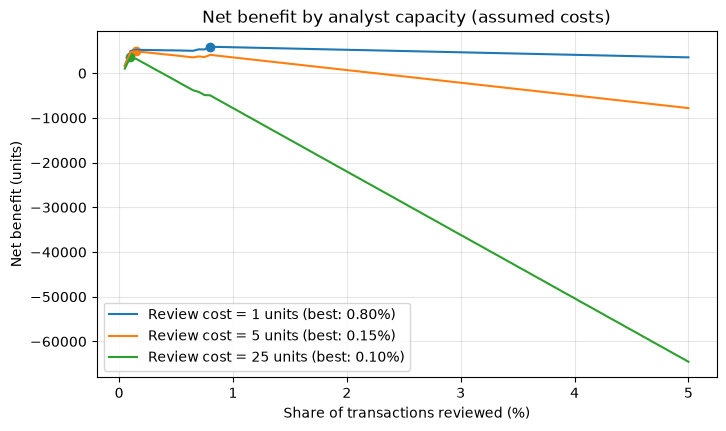

Total amount of frauds in the test set: 7728.0


In [11]:
def net_benefit_single(q, c):
    n = int(len(y_arr) * q)
    sel = order[:n]
    return amount_test[sel][y_arr[sel] == 1].sum() - c * n

qs = np.linspace(0.0005, 0.05, 100)
plt.figure(figsize=(8, 4.5))
for c in [1, 5, 25]:
    f = np.array([net_benefit_single(q, c) for q in qs])
    i = f.argmax()
    plt.plot(qs * 100, f, label=f'Review cost = {c} units (best: {qs[i] * 100:.2f}%)')
    plt.scatter(qs[i] * 100, f[i])
plt.xlabel('Share of transactions reviewed (%)')
plt.ylabel('Net benefit (units)')
plt.title('Net benefit by analyst capacity (assumed costs)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Total amount of frauds in the test set:", round(total_amount, 0))

### Final model: time-based test (single use)
- Final model: LightGBM without SMOTE. Test: the last 20% by time (56,746 transactions, 74 frauds, test rate 0.130%; random-model PR-AUC ≈ 0.0013). The test set was looked at only once.
- PR-AUC 0.770 (95% bootstrap interval 0.678-0.863), ROC-AUC 0.987 (0.975-0.996), top 0.5% capture 86.5% (78.7%-93.2%). Consistent with time-based CV (PR-AUC 0.770 ± 0.053).
- The intervals are wide because there are only 74 frauds; the bootstrap resamples transactions independently, so it ignores fraud clustering and the real uncertainty is probably larger.
- The test set covers the last ~7.7 hours of the data and its fraud rate is lower than in train; the results are a measurement for this window.

### Analyst capacity and net benefit (test set, assumed costs)
- Reviewing 0.10% of transactions (56) catches 50 of the 74 frauds (precision 89.3%, recall 67.6%); at 0.5% (283 transactions) it catches 64 (precision 22.6%, recall 86.5%); at 2% (1,134 transactions) it catches 66 (precision 5.8%, recall 89.2%). Returns diminish quickly.
- The share of fraud amount caught is lower than recall (at 0.5%: 69.6% vs 86.5%): the missed frauds are larger on average.
- Net benefit = fraud amount caught − review cost × transactions reviewed. With a review cost of 1 / 5 / 25 units the best review share is 0.80% / 0.15% / 0.10%.
- Limitations: the total fraud amount is 7,728 units over 74 frauds in a single 7.7-hour window; the optimum points are not exact. "Units" are used because the currency is not specified. Costs such as chargebacks and customer friction are not included. The review costs are assumptions, not real costs.

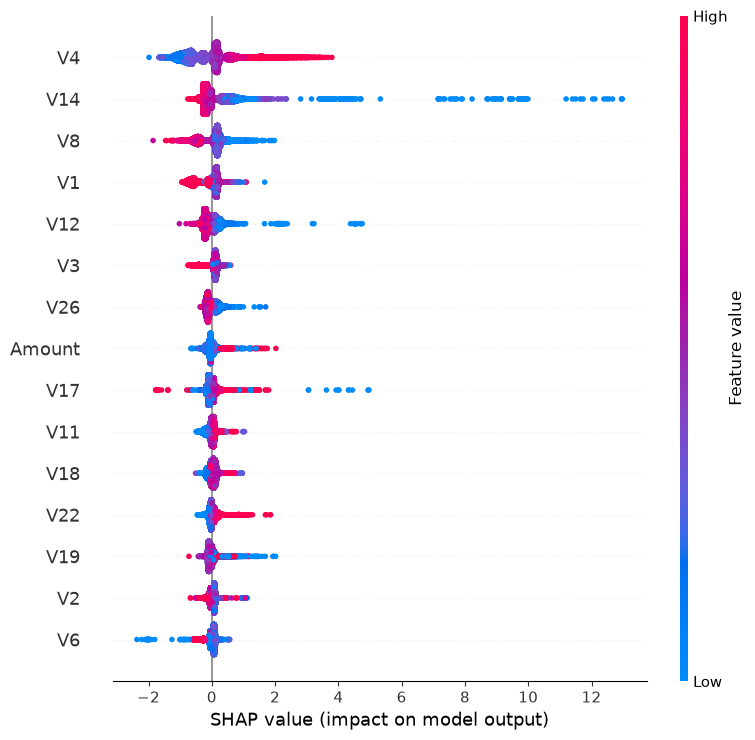

,All transactions,Frauds only
V14,0.308,7.066
V10,0.049,2.630
V4,0.573,2.060
V12,0.171,1.614
V17,0.089,0.767
V8,0.289,0.737
V28,0.060,0.616
V16,0.046,0.417
V20,0.043,0.389
V6,0.072,0.378


In [12]:
import shap

explainer = shap.TreeExplainer(final)
sv = explainer(X_test.astype(float))
vals = sv.values if sv.values.ndim == 2 else sv.values[:, :, 1]

shap.summary_plot(vals, X_test.astype(float), max_display=15, show=True)

imp_all = pd.Series(np.abs(vals).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
imp_fraud = pd.Series(np.abs(vals[y_arr == 1]).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
pd.DataFrame({'All transactions (mean |SHAP|)': imp_all.head(10).round(3), 'Frauds only': imp_fraud.head(10).round(3)})

table = pd.DataFrame({'All transactions': imp_all, 'Frauds only': imp_fraud})
table.sort_values('Frauds only', ascending=False).head(10).round(3)

### Explainability (SHAP, test set, final LightGBM)
- The features are anonymous PCA components (V1-V28); one can say which component matters, not what it means.
- Mean |SHAP| over all transactions: V4 0.573, V14 0.308, V8 0.289, V1 0.268, V12 0.171. Over frauds only (74 transactions): V14 7.066, V10 2.630, V4 2.060, V12 1.614, V17 0.767. The features that separate the frauds differ from the overall averages; V10 is 24th in the overall ranking.
- According to the beeswarm plot, the risk score rises when V14 and V12 are low and when V4 is high (SHAP values for V14 reach about 13).
- Amount ranks 8th overall (0.102) and 14th among frauds (not in the top 10).
- SHAP values are on the log-odds scale; the fraud averages rest on 74 transactions.

## Conclusion and Limitations

**Conclusion**
- 284,807 transactions, 492 frauds (0.173%). 1,081 fully duplicated rows (19 of them fraud) were removed; 283,726 transactions and 473 frauds remain. Time and Hour were not given to the model.
- Time split: train 226,980 transactions / 399 frauds, test 56,746 transactions / 74 frauds (the last ~7.7 hours of the data).
- ROC-AUC did not separate the models (even a single feature gives ~0.95); the primary metric is PR-AUC. In time-based CV, LightGBM PR-AUC is 0.770 ± 0.053, balanced logistic regression 0.651 ± 0.149, logistic regression 0.526 ± 0.192. Stratified CV is more optimistic (LightGBM 0.839 ± 0.054).
- SMOTE did not help LightGBM in time-based CV (0.770 → 0.753); scale_pos_weight=sqrt(ratio) was unstable; Isolation Forest (no labels) has PR-AUC 0.174 / 0.105, clearly below the supervised models.
- On the test set the final model (LightGBM without SMOTE) reaches PR-AUC 0.770 (95% interval 0.678-0.863), ROC-AUC 0.987, top 0.5% capture 86.5% (78.7%-93.2%).
- Analyst capacity: reviewing 0.10% of transactions catches 50 of the 74 frauds (precision 89.3%); 0.5% catches 64 (precision 22.6%); 2% catches 66.

**Limitations**
- A single ~48-hour window; the test set contains 74 frauds. The results are a measurement for this window and the uncertainty is wide. The bootstrap interval resamples transactions independently and ignores fraud clustering.
- That the duplicated rows are record duplicates is an inference, not verified.
- The features are anonymous PCA components: explainability is limited and no feature engineering was possible.
- Time/Hour were left out; the time-of-day effect cannot be separated from the two fraud bursts. The card-testing reading of the amount clusters (~0, ~1, ~100) is a hypothesis.
- No hyperparameter tuning for LightGBM; why scale_pos_weight is unstable was not investigated; the ranking of plain vs. balanced logistic regression changed with the scheme.
- The net benefit calculation is hypothetical and counts only the caught amount; the currency is unknown and chargeback and customer-friction costs are not included. The optimal review shares are not exact.
- The share of fraud amount caught is lower than recall (69.6% vs 86.5% at 0.5%): the missed frauds are larger on average; amount-weighted training was not tried.
- LightGBM results depend somewhat on the library version and run (a different environment gave slightly different LightGBM numbers than an earlier run of this analysis); read them as approximate.